# Add your own behaviour kernels
In this example, we will show how to turn on/off existing behaviour kernels, and how to create and include your own behaviour kernel to use in `plasticparcels` simulations. We will start by importing some necessary packages.

In [1]:
# Library imports
from datetime import datetime, timedelta

# Parcels and PlasticParcels imports
import plasticparcels as pp

# Plotting imports
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

## Load settings
We will first load in some model settings and define simulation settings in order to show how to add/remove behaviour kernels. For this simulation, we will release the particles at midnight on January 1st 2024. The particle trajectories will be 30 days long, saving the their position every 12 hours. We also set the advection timestep to 20 minutes. We will also download the necessary release location files (if they are not already downloaded).

In [2]:
# Load the model settings
settings_file = 'copernicus_marine.json'
settings = pp.utils.load_settings(settings_file)

# Download the mask and release data
settings = pp.utils.download_plasticparcels_dataset('NEMO0083', settings, 'input_data')

/Users/erik/Codes/plasticparcels/plasticparcels/utils.py:168: UserWarning: Could not set settings path ('unbeaching', 'filename') for dataset 'NEMO0083'.
  warnings.warn(f"Could not set settings path {settings_path} for dataset {dataset!r}.", stacklevel=1)


In [3]:
# Create the simulation settings
settings['simulation'] = {
    'startdate': datetime(2024, 1, 1),       # Start date of simulation
    'runtime': timedelta(days=60),           # Runtime of simulation
    'outputdt': timedelta(hours=12),         # Timestep of output
    'dt': timedelta(minutes=20),             # Timestep of advection

    # Specific to copernicusmarine datasets, provide a bounding box and depth range for your simulation
    'boundingbox': [ 5.0, 20.0, 30.0, 46.0], # Bounding box of simulation [lonmin, lonmax, latmin, latmax]}
    'depth_range': [0, 500],                 # Depth range of simulation [depthmin, depthmax] in meters
}

# Turn off verbose output
settings['ocean']['verbose_progress'] = False

## To turn on/off existing kernels
There are a number of existing behaviours that can be turned on/off in the settings. Let's first look at what behaviours can be included. We use `boolean` values to determine which behaviours are on/off. 

In [4]:
for key_value in [(key, value) for key, value in settings.items() if 'use_' in key.lower()]:
    print(key_value)

('use_3D', False)
('use_mixing', False)
('use_biofouling', False)
('use_stokes', True)
('use_wind', False)


Here, 3D advection is 'on', while vertical mixing, biofouling, Stokes drift, and wind-induced drift have been turned off. To turn these behaviours on, we simply set their values to `True`. For example:

In [5]:
settings['use_3D'] = True
settings['use_biofouling'] = True
settings['use_stokes'] = True

Note: These settings must be applied before creating the fieldset. If you change these settings later, you must reconstruct the fieldset.

In [6]:
# Create the fieldset
fieldset = pp.constructors.create_fieldset(settings)

INFO - 2026-11-13T15:27:58Z - Selected dataset version: "202406"
INFO - 2026-11-13T15:27:58Z - Selected dataset part: "default"
WARNING - 2026-11-13T15:27:58Z - Some of your subset selection [0.0, 500.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
INFO - 2026-11-13T15:27:59Z - Selected dataset version: "202406"
INFO - 2026-11-13T15:27:59Z - Selected dataset part: "default"
WARNING - 2026-11-13T15:27:59Z - Some of your subset selection [0.0, 500.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
INFO - 2026-11-13T15:28:01Z - Selected dataset version: "202406"
INFO - 2026-11-13T15:28:01Z - Selected dataset part: "default"
WARNING - 2026-11-13T15:28:01Z - Some of your subset selection [0.0, 500.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
INFO - 2026-11-13T15:28:03Z - Selected dataset version: "202406"
INFO - 2026-11-13T15:28:03Z - Selected da

INFO: No depth dimension found in dataset. Assuming surface data and adding a singleton depth dimension.


INFO - 2026-11-13T15:28:07Z - Selected dataset version: "202311"
INFO - 2026-11-13T15:28:07Z - Selected dataset part: "default"
WARNING - 2026-11-13T15:28:07Z - Some of your subset selection [0.0, 500.0] for the depth dimension exceed the dataset coordinates [0.4940253794193268, 5727.91650390625]
INFO - 2026-11-13T15:28:09Z - Selected dataset version: "202311"
INFO - 2026-11-13T15:28:09Z - Selected dataset part: "default"
WARNING - 2026-11-13T15:28:09Z - Some of your subset selection [0.0, 500.0] for the depth dimension exceed the dataset coordinates [0.4940253794193268, 5727.91650390625]
INFO - 2026-11-13T15:28:10Z - Selected dataset version: "202411"
INFO - 2026-11-13T15:28:10Z - Selected dataset part: "default"
WARNING - 2026-11-13T15:28:10Z - Some of your subset selection [0.0, 500.0] for the depth dimension exceed the dataset coordinates [0.4940253794193268, 5727.91650390625]
INFO - 2026-11-13T15:28:12Z - Selected dataset version: "202411"
INFO - 2026-11-13T15:28:12Z - Selected da

INFO: No depth dimension found in dataset. Assuming surface data and adding a singleton depth dimension.


## Set the particle settings
In our simulation, we will release particles in locations where there has been fishing related activities of boats registered from Tunisia. Some locations of fishing will exist beyond our domain, these particles will simply be deleted due to an out of bounds error.

In [7]:
# Create the plastic type settings
settings['plastictype'] = {
    'wind_coefficient' : 0.0, # Percentage of wind to apply to particles
    'plastic_diameter' : 0.001, # Plastic particle diameter (m)
    'plastic_density' : 1028., # Plastic particle density (kg/m^3)
}

# Create the particle release settings
settings['release'] = {
    'initialisation_type': 'fisheries',
    'country': 'Tunisia',
}

In [8]:
# Create the particleset
pset = pp.constructors.create_particleset_from_map(fieldset, settings)

## Create a `Kernel` list
The virtual plastic particles will experience any behaviour that we apply to it. `plasticparcels` contains a few prebuilt behaviours (see [here](https://plastic.parcels-code.org/en/latest/physicskernels.html) for more details). To use these behaviours, we must include a list of `Kernel` objects. Each `Kernel` describes some physics behaviour to be applied. To include the prebuilt kernels, we use the `constructors.create_kernel()` method.

In [9]:
# Create the applicable kernels to the plastic particles
kernels = pp.constructors.create_kernel(fieldset)

In [10]:
# Print the list fo kernels being applied
for kernel in kernels:
    print(kernel)

<function PolyTEOS10_bsq at 0x17ae25010>
<function AdvectionRK4_3D at 0x1797aac40>
<function Biofouling at 0x17ae24f60>
<function StokesDrift at 0x17acf6400>
<function checkThroughBathymetry at 0x17ae25380>
<function checkErrorThroughSurface at 0x17ae25590>
<function periodicBC at 0x17ae254e0>
<function deleteParticle at 0x17ae25640>


Here, we have a number of kernels that will be applied to our virtual plastic particles. We can run our simulation using the code as follows:

In [11]:
# Define the runtime, the timestepping, and the output frequency of the simulation from the settings
runtime = settings['simulation']['runtime']
dt = settings['simulation']['dt']
outputdt = settings['simulation']['outputdt']

# Create the particle file where output will be stored
pfile = pp.ParticleFile('example_Tunisia_fisheries_prebuilt.parquet', settings=settings, outputdt=outputdt, mode="w")

# Execute the simulation
pset.execute(kernels, runtime=runtime, dt=dt, output_file=pfile)

INFO: Output files are stored in example_Tunisia_fisheries_prebuilt.parquet
Integration time: 2024-02-29T12:00:00 100%|██████████| [08:14<00:00, 10474.80it/s] 


Let's plot the trajectories of these particles.

/Users/erik/Codes/plasticparcels/.pixi/envs/default/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


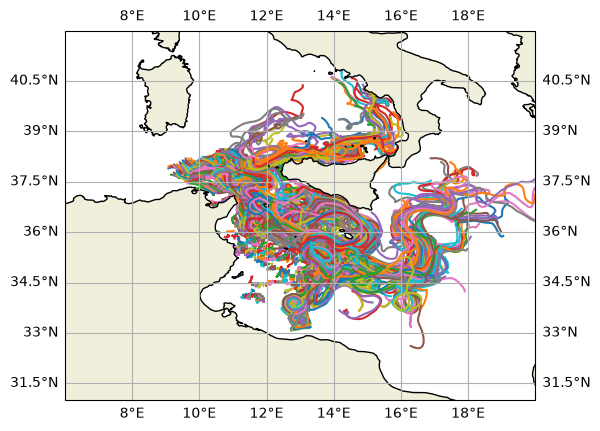

In [12]:
# Plot the trajectories
df = pp.read_particlefile('example_Tunisia_fisheries_prebuilt.parquet')


ax = plt.subplot(111, projection=ccrs.PlateCarree())
for traj in df.partition_by("particle_id", maintain_order=True):
    ax.plot(traj["x"], traj["y"], "-", transform=ccrs.PlateCarree(), zorder=0)
ax.add_feature(cfeature.LAND, zorder=1)
ax.coastlines(zorder=2)
ax.gridlines(draw_labels=True, zorder=3)
ax.set_extent([6, 20, 31, 42], crs=ccrs.PlateCarree())
plt.show()

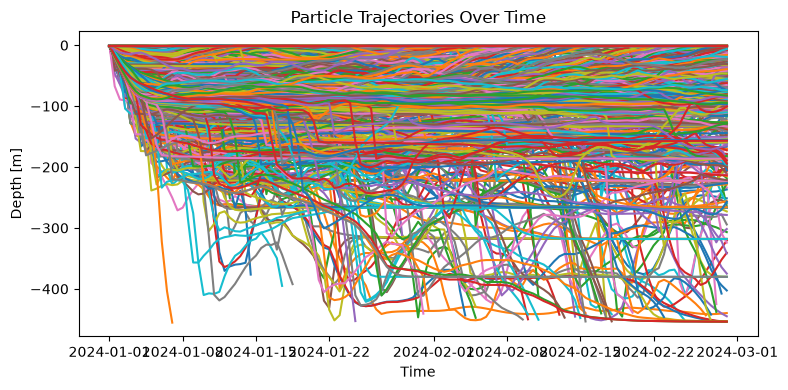

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
for trajectory in df.partition_by("particle_id"):
    ax.plot(trajectory["t"], -trajectory["z"])
ax.set_xlabel("Time")
ax.set_ylabel("Depth [m]")
ax.set_title("Particle Trajectories Over Time")
fig.tight_layout()
plt.show()

## Implementing your own kernel
In the case you want to include your own kernel or modify an existing kernel, you simply need to define your kernel and include it in the list of kernels. More details on how this works can be found [here](https://docs.parcels-code.org/en/latest/examples/tutorial_kernelloop.html).

Note: You must include the kernel before the error checking kernels, which are currently the last five kernels.

In [14]:
# An example kernel that applies a constant northward drift to particles
def NortheastwardDrift(particles, fieldset):
    # Only apply Northward drift if the particle is moving in the ocean
    (ocean_u, ocean_v) = fieldset.UV[particles]
    ptcls = particles[np.sqrt(ocean_u**2 + ocean_v**2) > 1e-10]
    ptcls.dy += 1e-3  # Units of degrees
    ptcls.dx += 1e-3

In [15]:
# Create the particleset
pset = pp.constructors.create_particleset_from_map(fieldset, settings)

# Create the applicable kernels to the plastic particles
kernels = pp.constructors.create_kernel(fieldset)

# Print the list fo kernels being applied
for kernel in kernels:
    print(kernel)

<function PolyTEOS10_bsq at 0x17ae25010>
<function AdvectionRK4_3D at 0x1797aac40>
<function Biofouling at 0x17ae24f60>
<function StokesDrift at 0x17acf6400>
<function checkThroughBathymetry at 0x17ae25380>
<function checkErrorThroughSurface at 0x17ae25590>
<function periodicBC at 0x17ae254e0>
<function deleteParticle at 0x17ae25640>


In [16]:
# Insert our new kernels into the list of kernels, but before the error kernels
kernels.insert(4, NortheastwardDrift)

for kernel in kernels:
    print(kernel)

<function PolyTEOS10_bsq at 0x17ae25010>
<function AdvectionRK4_3D at 0x1797aac40>
<function Biofouling at 0x17ae24f60>
<function StokesDrift at 0x17acf6400>
<function NortheastwardDrift at 0x349fed6f0>
<function checkThroughBathymetry at 0x17ae25380>
<function checkErrorThroughSurface at 0x17ae25590>
<function periodicBC at 0x17ae254e0>
<function deleteParticle at 0x17ae25640>


Execute the simulation.

In [17]:
# Create the particle file where output will be stored
pfile = pp.ParticleFile('example_Tunisia_fisheries_custom.parquet', settings=settings, outputdt=outputdt, mode="w")

# Execute the simulation
pset.execute(kernels, runtime=runtime, dt=dt, output_file=pfile)

INFO: Output files are stored in example_Tunisia_fisheries_custom.parquet
Integration time: 2024-02-29T12:00:00 100%|██████████| [02:26<00:00, 35365.64it/s]


/Users/erik/Codes/plasticparcels/.pixi/envs/default/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/erik/Codes/plasticparcels/.pixi/envs/default/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


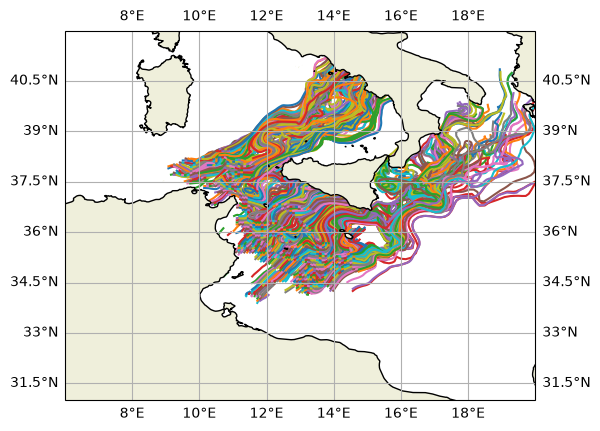

In [18]:
# plot the particle trajectories with the custom NortheastwardDrift kernel applied
df = pp.read_particlefile('example_Tunisia_fisheries_custom.parquet')


ax = plt.subplot(111, projection=ccrs.PlateCarree())
for traj in df.partition_by("particle_id", maintain_order=True):
    ax.plot(traj["x"], traj["y"], "-", transform=ccrs.PlateCarree(), zorder=0)
ax.add_feature(cfeature.LAND, zorder=1)
ax.coastlines(zorder=2)
ax.gridlines(draw_labels=True, zorder=3)
ax.set_extent([6, 20, 31, 42], crs=ccrs.PlateCarree())
plt.show()